### 05 - Ανάλυση λαθών (FN/FP) και πειράματα βελτίωσης στο validation
Τελικό μοντέλο: scale_pos_weight, Optuna Β, εκπαιδευμένο στο train_fit (1991-1999), αξιολόγηση στο validation (2000-2001).
Το test δεν χρησιμοποιείται σε αυτό το notebook.

In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, ndcg_score
import shap
from scipy.stats import mannwhitneyu

RANDOM_STATE = 42
pd.set_option('display.max_rows', None)   # να φαίνονται όλες οι γραμμές
pd.set_option('display.width', 250)       # να χωράνε οι πίνακες σε πλάτος

# Φόρτωση των συνόλων από το 03_models (το test δεν χρειάζεται εδώ)
train_fit = pd.read_pickle("train_fit.pkl")
valid     = pd.read_pickle("valid.pkl")
print("train_fit:", train_fit.shape, "| valid:", valid.shape)

# Μεταβλητές εισόδου: raw_scaled (25 raw / ενεργητικό + at, prcc_f, csho)
raw_cols = ['act','ap','at','ceq','che','cogs','csho','dlc','dltis','dltt','dp','ib',
            'invt','ivao','ivst','lct','lt','ni','ppegt','pstk','re','rect','sale',
            'sstk','txp','txt','xint','prcc_f']
keep_as_is = ['at', 'prcc_f', 'csho']
scaled_cols = []
for c in raw_cols:
    if c not in keep_as_is:
        scaled_cols.append(c + '_at')
raw_scaled = scaled_cols + keep_as_is
print("Πλήθος raw_scaled:", len(raw_scaled))   # πρέπει 28

# Ρυθμίσεις του Optuna από το 04 (δεν ξανατρέχει το Optuna)
best_params = pd.read_pickle("optuna_best_params.pkl")
print("Τελικό μοντέλο (B_spw):", best_params['B_spw'])

train_fit: (54052, 78) | valid: (13114, 78)
Πλήθος raw_scaled: 28
Τελικό μοντέλο (B_spw): {'scale_pos_weight': 1.2883333782360646, 'n_estimators': 1057, 'learning_rate': 0.011875020655065738, 'max_depth': 4, 'min_child_weight': 3.852260948765374, 'subsample': 0.6771006305632494, 'colsample_bytree': 0.8851320845005959}


In [ ]:
# Ορίζει δύο συναρτήσεις που χρησιμοποιούνται σε όλο το notebook: το NDCG@1% (ανά έτος και μετά μέσος όρος) και τα TP/FP/FN όταν ελέγχονται οι 100 πιο ύποπτες εταιρείες κάθε έτους, δηλαδή η πολιτική της ρυθμιστικής αρχής.
# NDCG@1%: ανά έτος, k = 1% των παρατηρήσεων του έτους, μέσος όρος των ετών
def ndcg_1pct(data, prediction):
    scores = []
    for year in sorted(data['fyear'].unique()):
        year_mask = (data['fyear'] == year).values
        k = round(0.01 * year_mask.sum())
        score = ndcg_score([data.loc[year_mask, 'misstate']], [prediction[year_mask]], k=k)
        scores.append(score)
    return np.mean(scores)

# TP / FP / FN όταν ελέγχονται οι k πιο ύποπτες εταιρείες κάθε έτους
def confusion_top_k(data, prediction, k=100):
    tp, fp, fn = 0, 0, 0
    for year in sorted(data['fyear'].unique()):
        year_mask = (data['fyear'] == year).values
        y_year = data.loc[year_mask, 'misstate'].values
        p_year = prediction[year_mask]
        order = np.argsort(-p_year)
        checked = np.zeros(len(p_year), dtype=bool)
        checked[order[:k]] = True
        tp += (checked & (y_year == 1)).sum()
        fp += (checked & (y_year == 0)).sum()
        fn += (~checked & (y_year == 1)).sum()
    return tp, fp, fn

### **ΑΝΑΛΥΣΗ ΛΑΘΩΝ ΣΤΟ VALIDATION**

In [4]:
# Τελικό μοντέλο (spw, Optuna Β) εκπαιδευμένο στο train_fit -> πιθανότητες στο validation
model_final = XGBClassifier(random_state=RANDOM_STATE, **best_params['B_spw'])
model_final.fit(train_fit[raw_scaled], train_fit['misstate'])

valid_err = valid.copy()
valid_err['prob'] = model_final.predict_proba(valid[raw_scaled])[:, 1]

# Θέση κάθε εταιρείας στη λίστα του έτους της (1 = η πιο ύποπτη)
valid_err['rank'] = valid_err.groupby('fyear')['prob'].rank(ascending=False, method='first')
valid_err['checked'] = valid_err['rank'] <= 100      # οι 100 πρώτες ανά έτος ελέγχονται

# Ομάδα κάθε εταιρείας
valid_err['group'] = 'TN'
valid_err.loc[valid_err['checked'] & (valid_err['misstate'] == 1), 'group'] = 'TP'
valid_err.loc[valid_err['checked'] & (valid_err['misstate'] == 0), 'group'] = 'FP'
valid_err.loc[~valid_err['checked'] & (valid_err['misstate'] == 1), 'group'] = 'FN'
print(valid_err['group'].value_counts())

# Πού βρίσκονται οι χαμένες απάτες στη λίστα;
fn = valid_err[valid_err['group'] == 'FN']
print("\nΘέση των FN στη λίστα του έτους τους:")
print(fn['rank'].describe().round(0))
print("FN στις θέσεις 101-300:", (fn['rank'] <= 300).sum(), "από", len(fn))

group
TN    12772
FP      175
FN      142
TP       25
Name: count, dtype: int64

Θέση των FN στη λίστα του έτους τους:
count     142.0
mean     1622.0
std      1550.0
min       102.0
25%       422.0
50%      1047.0
75%      2456.0
max      6626.0
Name: rank, dtype: float64
FN στις θέσεις 101-300: 27 από 142


 Από τις 167 απάτες βρέθηκαν 25 και χάθηκαν 142. Μόνο 27 FN ήταν κοντά στο όριο (θέσεις 101–300). Η διάμεσος θέση των FN είναι 1.047 και το ένα τέταρτο βρίσκεται πέρα από τη θέση 2.456, άρα οι περισσότερες χαμένες απάτες δεν χάθηκαν «για λίγο».

In [5]:
# Οι 167 απάτες του validation χωρισμένες με βάση τη θέση τους στη λίστα του έτους
frauds = valid_err[valid_err['misstate'] == 1].copy()
frauds['θέση'] = pd.cut(frauds['rank'], bins=[0, 100, 300, 2500, np.inf],
                        labels=['1. TP (1-100)', '2. FN παραλίγο (101-300)',
                                '3. FN μεσαίες (301-2500)', '4. FN αόρατες (>2500)'])
                    
# Πόσες απάτες από κάθε ομάδα σε κάθε κατηγορία μεγέθους (1 = μικρότερες, 5 = μεγαλύτερες)
print(pd.crosstab(frauds['θέση'], frauds['size_nyse'], margins=True))

print()   

# Διάμεσος χρηματιστηριακής αξίας ανά ομάδα
print(frauds.groupby('θέση', observed=True)['mkt_val'].median().round(1))

print() 

# Ποσοστά ανά γραμμή: πώς μοιράζεται κάθε ομάδα στις κατηγορίες μεγέθους (κάθε γραμμή = 100%)
print((pd.crosstab(frauds['θέση'], frauds['size_nyse'], normalize='index') * 100).round(1))

# Ποσοστό απατών που βρέθηκαν (TP) σε κάθε κατηγορία μεγέθους
found_rate = (frauds['group'] == 'TP').groupby(frauds['size_nyse']).mean() * 100
print("\nΠοσοστό απατών που βρέθηκαν ανά κατηγορία μεγέθους (%):")
print(found_rate.round(1))

size_nyse                  1   2   3   4   5  All
θέση                                             
1. TP (1-100)              1   3   1   5  15   25
2. FN παραλίγο (101-300)   3   4   5   2  13   27
3. FN μεσαίες (301-2500)  17  19  14  11  20   81
4. FN αόρατες (>2500)     20   6   5   1   2   34
All                       41  32  25  19  50  167

θέση
1. TP (1-100)               7652.3
2. FN παραλίγο (101-300)    3633.0
3. FN μεσαίες (301-2500)    1050.1
4. FN αόρατες (>2500)        134.8
Name: mkt_val, dtype: float64

size_nyse                    1     2     3     4     5
θέση                                                  
1. TP (1-100)              4.0  12.0   4.0  20.0  60.0
2. FN παραλίγο (101-300)  11.1  14.8  18.5   7.4  48.1
3. FN μεσαίες (301-2500)  21.0  23.5  17.3  13.6  24.7
4. FN αόρατες (>2500)     58.8  17.6  14.7   2.9   5.9

Ποσοστό απατών που βρέθηκαν ανά κατηγορία μεγέθους (%):
size_nyse
1     2.4
2     9.4
3     4.0
4    26.3
5    30.0
Name: group, dtype: float6

Παρατηρούμε ότι οι περισσότερες "αόρατες" είναι οι πολύ μικρες εταιρείες της κατηγορίας 1 καθώς βρέθηκε μόνο 1 απατη από τις 41 φτάνοντας το 58,8 % των FN. Οι περισσότερες εταιρείες που εντποπίστηκαν ήταν στην κατηγορία 5 (15/25)με ποσοστό 60%. Παρατηρούμε επίσης ότι εταιρείες της κατηγορίας 5 όσο πεφτει η θέση στη λίστα τόσο μειώνεται το ποσοτό συμμετοχής της ενώ στις εταιρείες στην κατηγορία 1 συμβαίνει το αντίθετο. Για τις κατηγορίες 2,3 και 4 η κατηγορία 2 έχει τη μεγαλύτερη συμμετοχή στις μεσαίες θέσεις με 23,5%, η 3 στις θέσεις λίγο κάτω από τη λίστα με18,5% ενώ η 4 έχει το μεγαλύτερο ποσοστό (20%) στα TP.

In [6]:
pd.set_option('display.max_rows', None)   # να φαίνονται όλες οι γραμμές

# Οι «αόρατες» απάτες σε σύγκριση με μη απάτες ιδιού μεγέθους (κατηγορίες 1-2)
small = valid_err[valid_err['size_nyse'].isin([1, 2])]
small_inv = small[(small['misstate'] == 1) & (small['rank'] > 2500)]
small_tn = small[small['group'] == 'TN']
print("Αόρατες μικρές απάτες:", len(small_inv), "| Μικρές μη απάτες:", len(small_tn))

comp = pd.DataFrame({'Αόρατες απάτες': small_inv[raw_scaled].median(),
                     'Μη απάτες': small_tn[raw_scaled].median()})
comp['Διαφορά'] = comp['Αόρατες απάτες'] - comp['Μη απάτες']   # θετικό = οι αόρατες απάτες έχουν μεγαλύτερη τιμή
print(comp.round(4))

Αόρατες μικρές απάτες: 26 | Μικρές μη απάτες: 10130
          Αόρατες απάτες  Μη απάτες  Διαφορά
act_at            0.6006     0.5225   0.0781
ap_at             0.0578     0.0828  -0.0249
ceq_at            0.6451     0.4567   0.1884
che_at            0.1155     0.0854   0.0301
cogs_at           0.7664     0.5969   0.1694
dlc_at            0.0090     0.0263  -0.0173
dltis_at          0.0000     0.0000   0.0000
dltt_at           0.0694     0.0552   0.0142
dp_at             0.0435     0.0485  -0.0050
ib_at             0.0073    -0.0615   0.0689
invt_at           0.1627     0.0442   0.1185
ivao_at           0.0000     0.0000   0.0000
ivst_at           0.0000     0.0000   0.0000
lct_at            0.1928     0.2544  -0.0615
lt_at             0.3549     0.5171  -0.1622
ni_at             0.0073    -0.0613   0.0686
ppegt_at          0.3696     0.4189  -0.0493
pstk_at           0.0000     0.0000   0.0000
re_at            -0.0042    -0.3078   0.3036
rect_at           0.0850     0.1247  -0.0396
sal

Παρατηρούμε ότι οι  περισσότερες διαφορές είναι κάτω από 0,1, για 5 μεταβλητές η διαφορά κινείται από 0,1-0,3 και για μόλις 3 μεταβλητές η διαφορά είναι πα΄νω από τη μονάδα.
Οι αόρατες απάτες έχουν πιο «υγιές» προφίλ από τις μη απάτες ίδιου μεγέθους: θετικά κέρδη (ni_at 0,007 έναντι −0,061), λιγότερες υποχρεώσεις (lt_at 0,35 έναντι 0,52), καλύτερα αποτελέσματα εις νέον (re_at −0,004 έναντι −0,308), περισσότερα αποθέματα, πωλήσεις και μετρητά. Τίποτα στο προφίλ τους δεν δείχνει απάτη. Οι διαφορές στα at, prcc_f και csho είναι σε άλλη κλίμακα (εκατομμύρια, δολάρια), οπότε δεν συγκρίνονται με αυτές των δεικτών.

In [7]:
# Επιλογή Α: ίδιο μοντέλο χωρίς τα 3 μεγέθη (at, csho, prcc_f) -> μόνο οι 25 μεγέθη / ενεργητικό
model_A = XGBClassifier(random_state=RANDOM_STATE, **best_params['B_spw'])
model_A.fit(train_fit[scaled_cols], train_fit['misstate'])
prob_A = model_A.predict_proba(valid[scaled_cols])[:, 1]

tp, fp, fn = confusion_top_k(valid, prob_A, k=100)
print("Χωρίς μεγέθη | AUC:", round(roc_auc_score(valid['misstate'], prob_A), 4),
      "| NDCG@1%:", round(ndcg_1pct(valid, prob_A), 4), "| TP:", tp, "| FP:", fp, "| FN:", fn)
print("Τελικό       | AUC: 0.7942 | NDCG@1%: 0.142 | TP: 25 | FP: 175 | FN: 142")

# Σε ποιες κατηγορίες μεγέθους είναι τώρα οι απάτες που βρέθηκαν (True) και αυτές που χάθηκαν (False)
rank_A = pd.Series(prob_A, index=valid.index).groupby(valid['fyear']).rank(ascending=False, method='first')
fraud = valid['misstate'] == 1
print(pd.crosstab(valid.loc[fraud, 'size_nyse'], (rank_A <= 100)[fraud], margins=True))

Χωρίς μεγέθη | AUC: 0.7438 | NDCG@1%: 0.0773 | TP: 13 | FP: 187 | FN: 154
Τελικό       | AUC: 0.7942 | NDCG@1%: 0.142 | TP: 25 | FP: 175 | FN: 142
col_0      False  True  All
size_nyse                  
1             40     1   41
2             27     5   32
3             24     1   25
4             17     2   19
5             46     4   50
All          154    13  167


Από τα  προηγουμενα κελια βγηκε οτι οι TP είναι μεγάλες εταιρείες και οι αόρατες FN μικρές. Τα at, csho και prcc_f είναι οι μόνες μεταβλητές του μοντέλου που δεν διαιρέθηκαν με το ενεργητικό, άρα οι μόνες που κουβαλούν το μέγεθος.Ισως το μοντέλο στηρίζεται τόσο στο «μεγάλη εταιρεία = ύποπτη» που σπρώχνει τις μικρές απάτες στο τέλος της λίστας, ακόμα κι αν οι δείκτες τους είναι ύποπτοι. Αν βγάλουμε το μέγεθος, το μοντέλο αναγκάζεται να κατατάξει μόνο με τους δείκτες, και θα φανεί αν τότε βρίσκει μικρές απάτες. Δεν τις βρήκε (1 στην κατηγορία 1, όπως πριν), άρα η υπόθεση απορρίφθηκε καθώς οι μικρές απάτες δεν χάνονται επειδή τις «πνίγει» το μέγεθος, αλλά επειδή και οι δείκτες τους μοιάζουν κανονικοί.

In [8]:
# Εύρη των μεταβλητών για μη απάτες (TN), χαμένες απάτες (FN) και απάτες που βρέθηκαν (TP)
rows = []
for col in raw_scaled:
    tn = valid_err.loc[valid_err['group'] == 'TN', col]
    fn = valid_err.loc[valid_err['group'] == 'FN', col]
    tp = valid_err.loc[valid_err['group'] == 'TP', col]
    low, high = tn.quantile(0.05), tn.quantile(0.95)    # «κανονικό» εύρος των μη απατών

#παιρνω το 25%-75% για να δω που βρισκεται η τυπικη εταιρεια καθε ομαδας
    rows.append({'Μεταβλητή': col,
                 'TN 25%-75%': f"{tn.quantile(0.25):.3f} έως {tn.quantile(0.75):.3f}",
                 'FN 25%-75%': f"{fn.quantile(0.25):.3f} έως {fn.quantile(0.75):.3f}",
                 'TP 25%-75%': f"{tp.quantile(0.25):.3f} έως {tp.quantile(0.75):.3f}",
                 'FN μέσα στο 5-95% TN (%)': round(fn.between(low, high).mean() * 100, 1), #τι ποσοστό των χαμένων απατών έχει τιμή μέσα σε αυτό το φυσιολογικό εύρος.
                 'TP μέσα στο 5-95% TN (%)': round(tp.between(low, high).mean() * 100, 1)}) #πόσες απάτες που βρέθηκαν έχουν φυσιολογική τιμή.

ranges = pd.DataFrame(rows).set_index('Μεταβλητή')
pd.set_option('display.width', 250)      # να χωράει ο πίνακας σε πλάτος
print(ranges)

                   TN 25%-75%            FN 25%-75%              TP 25%-75%  FN μέσα στο 5-95% TN (%)  TP μέσα στο 5-95% TN (%)
Μεταβλητή                                                                                                                      
act_at        0.268 έως 0.712       0.289 έως 0.591         0.347 έως 0.586                      94.4                      96.0
ap_at         0.037 έως 0.148       0.024 έως 0.112         0.070 έως 0.149                      91.5                     100.0
ceq_at        0.231 έως 0.691       0.291 έως 0.679         0.242 έως 0.557                      97.9                     100.0
che_at        0.019 έως 0.280       0.014 έως 0.209         0.021 έως 0.081                      95.8                     100.0
cogs_at       0.219 έως 1.040       0.213 έως 0.860         0.389 έως 1.148                      96.5                     100.0
dlc_at        0.001 έως 0.103       0.002 έως 0.050         0.011 έως 0.071                      99.3   

Παρατηρούμε ότι at (ενεργητικό): FN 79,6%, TP 44%.
Από τις απάτες που βρέθηκαν, μόνο το 44% έχει φυσιολογικό μέγεθος. Οι υπόλοιπες, το 56%, είναι ασυνήθιστα μεγάλες, μεγαλύτερες από το 95% των κανονικών εταιρειών.
Από τις χαμένες, το 79,6% έχει φυσιολογικό μέγεθος και για αυτο ΄χανονται
Στους 25 δείκτες προς το ενεργητικό όλα τα ποσοστά είναι γύρω στο 90% ή πάνω. Οι απάτες δεν ξεχωρίζουν σε καμία μεταβλητή χωριστά. Ξεχωρίζουν μόνο στο μέγεθος (at, csho, prcc_f), και κυρίως αυτές που βρέθηκαν.

In [9]:
# Ανά εταιρεία: σε πόσες από τις 28 μεταβλητές βγαίνει έξω από το εύρος 5%-95% των μη απατών
tn_values = valid_err.loc[valid_err['group'] == 'TN', raw_scaled]
low = tn_values.quantile(0.05)
high = tn_values.quantile(0.95)

outside = (valid_err[raw_scaled] < low) | (valid_err[raw_scaled] > high)   # True = έξω από το εύρος
valid_err['n_outside'] = outside.sum(axis=1)                                 # πόσες μεταβλητές έξω, ανά εταιρεία

print("\nΠοσοστό (%) εταιρειών μέσα στο εύρος σε ΟΛΕΣ τις μεταβλητές:")
print(((valid_err['n_outside'] == 0).groupby(valid_err['group']).mean() * 100).round(1))


Ποσοστό (%) εταιρειών μέσα στο εύρος σε ΟΛΕΣ τις μεταβλητές:
group
FN    31.7
FP    28.0
TN    29.0
TP    24.0
Name: n_outside, dtype: float64


Παρατηρουμε οτι οι FN εταιρείες έχουν το μεγαλύτερο ποσοστό άρα παρουσιάζονται ως οι πιο "κανονικες" και αδυνατεί να τις βρει το μοντέλο.

### **ΠΕΙΡΑΜΑ: ΜΕΤΑΒΛΗΤΕΣ ΤΑΣΗΣ**

In [10]:
# Μεταβλητές τάσης: μεταβολή 1 έτους και 3 ετών (μόνο για το πείραμα, το 02 δεν αλλάζει)
size_vars  = ['at', 'prcc_f', 'csho']                                                 # ποσοστιαία μεταβολή
ratio_vars = ['ppegt_at', 're_at', 'dp_at', 'che_at', 'sstk_at', 'invt_at', 'sale_at']  # απλή διαφορά

# Ένωση train_fit + valid, ώστε κάθε εταιρεία να έχει όλες τις χρονιές της (1991-2001) στη σειρά
both = pd.concat([train_fit, valid]).sort_values(['gvkey', 'fyear'])

for k in [1, 3]:
    # Η γραμμή k θέσεις πίσω πρέπει να είναι ακριβώς η χρονιά fyear - k, αλλιώς λείπουν χρονιές
    prev_year = both.groupby('gvkey')['fyear'].shift(k)
    gap = prev_year != both['fyear'] - k

    for col in size_vars + ratio_vars:
        prev = both.groupby('gvkey')[col].shift(k)       # τιμή της ίδιας εταιρείας k χρόνια πριν
        prev[gap] = np.nan

        if col in size_vars:
            new = (both[col] - prev) / prev              # ποσοστιαία μεταβολή (ανάπτυξη)
        else:
            new = both[col] - prev                       # απλή διαφορά (είναι ήδη λόγοι)

        both[col + '_ch' + str(k)] = new.replace([np.inf, -np.inf], np.nan)

# Λίστες με τα ονόματα των νέων στηλών
trend_1 = []
trend_3 = []
for col in size_vars + ratio_vars:
    trend_1.append(col + '_ch1')
    trend_3.append(col + '_ch3')

# Ξαναχωρισμός με βάση το έτος
train_fit_tr = both[both['fyear'] <= 1999]
valid_tr     = both[both['fyear'] >= 2000]
print("train_fit:", train_fit_tr.shape, "| valid:", valid_tr.shape)

print("\nΠοσοστό κενών (%) στο validation:")
print((valid_tr[trend_1 + trend_3].isna().mean() * 100).round(1))

train_fit: (54052, 98) | valid: (13114, 98)

Ποσοστό κενών (%) στο validation:
at_ch1          15.1
prcc_f_ch1      14.8
csho_ch1        14.8
ppegt_at_ch1    15.3
re_at_ch1       15.3
dp_at_ch1       15.3
che_at_ch1      15.3
sstk_at_ch1     15.3
invt_at_ch1     15.3
sale_at_ch1     15.3
at_ch3          39.4
prcc_f_ch3      39.3
csho_ch3        39.3
ppegt_at_ch3    39.4
re_at_ch3       39.4
dp_at_ch3       39.4
che_at_ch3      39.4
sstk_at_ch3     39.4
invt_at_ch3     39.4
sale_at_ch3     39.4
dtype: float64


Κενά στις τάσεις 1 έτους: περίπου 15%. Είναι οι εταιρείες που μπαίνουν πρώτη χρονιά στο δείγμα ή έχουν κενή χρονιά πριν.
Κενά στις τάσεις 3 ετών: περίπου 39%. Πολλές εταιρείες δεν έχουν 3 συνεχόμενα χρόνια ιστορικού. 

In [11]:
# Πείραμα: τελικό μοντέλο (ίδιες ρυθμίσεις Β) χωρίς και με μεταβλητές τάσης
# Τελευταία δοκιμή τάσεων: μόνο οι 3 κορυφαίες μεταβλητές της permutation (prcc_f, ppegt_at, csho)
top3_1 = ['prcc_f_ch1', 'ppegt_at_ch1', 'csho_ch1']
top3_3 = ['prcc_f_ch3', 'ppegt_at_ch3', 'csho_ch3']

variants = {'Τελικό (raw_scaled)':      raw_scaled,
            '+ 3 τάσεις 1 έτους':       raw_scaled + top3_1,
            '+ 3 τάσεις 3 ετών':        raw_scaled + top3_3}

rows = []
found = {}
for name, cols in variants.items():
    model = XGBClassifier(random_state=RANDOM_STATE, **best_params['B_spw'])
    model.fit(train_fit_tr[cols], train_fit_tr['misstate'])
    prob = model.predict_proba(valid_tr[cols])[:, 1]

    tp, fp, fn = confusion_top_k(valid_tr, prob, k=100)
    rows.append({'Μοντέλο': name,
                 'AUC': roc_auc_score(valid_tr['misstate'], prob),
                 'NDCG@1%': ndcg_1pct(valid_tr, prob),
                 'TP': tp, 'FP': fp, 'FN': fn})

    # Απάτες που βρέθηκαν (στις 100 πρώτες του έτους) ανά κατηγορία μεγέθους
    rank = pd.Series(prob, index=valid_tr.index).groupby(valid_tr['fyear']).rank(ascending=False, method='first')
    is_tp = (rank <= 100) & (valid_tr['misstate'] == 1)
    found[name] = is_tp.groupby(valid_tr['size_nyse']).sum()

print(pd.DataFrame(rows).round(4))
print("\nΑπάτες που βρέθηκαν ανά κατηγορία μεγέθους (σύνολο απατών: 41 / 32 / 25 / 19 / 50):")
print(pd.DataFrame(found))

               Μοντέλο     AUC  NDCG@1%  TP   FP   FN
0  Τελικό (raw_scaled)  0.7942   0.1420  25  175  142
1   + 3 τάσεις 1 έτους  0.7874   0.1331  24  176  143
2    + 3 τάσεις 3 ετών  0.7985   0.1449  26  174  141

Απάτες που βρέθηκαν ανά κατηγορία μεγέθους (σύνολο απατών: 41 / 32 / 25 / 19 / 50):
           Τελικό (raw_scaled)  + 3 τάσεις 1 έτους  + 3 τάσεις 3 ετών
size_nyse                                                            
1                            1                   1                  1
2                            3                   4                  4
3                            1                   2                  1
4                            5                   4                  4
5                           15                  13                 16


Οι τάσεις 1 έτους χειροτερεύουν ελαφρά το μοντέλο (AUC 0,7874), ενώ οι τάσεις 3 ετών το βελτιώνουν ελάχιστα (AUC 0,7985 έναντι 0,7942, TP 26 έναντι 25). Στην κατηγορία 1 βρίσκεται και πάλι μόνο 1 απάτη.

In [12]:
# Έλεγχος σταθερότητας: τελικό έναντι «+ 3 τάσεις 3 ετών» με 3 seeds (όπως στο RUS)
seeds = [1, 21, 42]
rows = []
for name, cols in [('Τελικό (raw_scaled)', raw_scaled),
                   ('+ 3 τάσεις 3 ετών', raw_scaled + top3_3)]:
    for seed in seeds:
        model = XGBClassifier(random_state=seed, **best_params['B_spw'])
        model.fit(train_fit_tr[cols], train_fit_tr['misstate'])
        prob = model.predict_proba(valid_tr[cols])[:, 1]

        tp, fp, fn = confusion_top_k(valid_tr, prob, k=100)
        rows.append({'Μοντέλο': name, 'seed': seed,
                     'AUC': roc_auc_score(valid_tr['misstate'], prob),
                     'NDCG@1%': ndcg_1pct(valid_tr, prob),
                     'TP': tp})

seed_results = pd.DataFrame(rows)
print(seed_results.round(4))
print("\nΜέσος όρος 3 seeds:")
print(seed_results.groupby('Μοντέλο')[['AUC', 'NDCG@1%', 'TP']].mean().round(4))

               Μοντέλο  seed     AUC  NDCG@1%  TP
0  Τελικό (raw_scaled)     1  0.7921   0.1587  26
1  Τελικό (raw_scaled)    21  0.7878   0.1441  27
2  Τελικό (raw_scaled)    42  0.7942   0.1420  25
3    + 3 τάσεις 3 ετών     1  0.7969   0.1631  26
4    + 3 τάσεις 3 ετών    21  0.7946   0.1564  27
5    + 3 τάσεις 3 ετών    42  0.7985   0.1449  26

Μέσος όρος 3 seeds:
                        AUC  NDCG@1%       TP
Μοντέλο                                      
+ 3 τάσεις 3 ετών    0.7967   0.1548  26.3333
Τελικό (raw_scaled)  0.7913   0.1483  26.0000


**Αποτελέσματα (seed 42):**
- 10 τάσεις 1 έτους (3 μεγέθη + 7 σημαντικοί δείκτες): AUC 0,7827 → απορρίπτεται
- 10 τάσεις 3 ετών: AUC 0,7921 → απορρίπτεται
- 3 τάσεις 1 έτους (prcc_f, ppegt_at, csho): AUC 0,7874 → απορρίπτεται
- 3 τάσεις 3 ετών (prcc_f, ppegt_at, csho): AUC 0,7985 (τελικό 0,7942) → έλεγχος σταθερότητας

**Έλεγχος σταθερότητας (seeds 1, 21, 42):** οι 3 τάσεις 3 ετών είχαν υψηλότερο AUC και στα 3 seeds (+0,0048 / +0,0068 / +0,0043, μ.ό. 0,7967 έναντι 0,7913) και υψηλότερο NDCG@1% (μ.ό. 0,1548 έναντι 0,1483). Τα TP έμειναν πρακτικά ίδια (26,3 έναντι 26). Η βελτίωση είναι μικρή αλλά σταθερή και αφορά τη συνολική κατάταξη, όχι τις 100 πρώτες.

**Τι δεν άλλαξε:** στις μικρές εταιρείες (κατηγορία μεγέθους 1) βρέθηκε πάλι 1 από τις 41 απάτες σε όλες τις δοκιμές. Οι τάσεις δεν διορθώνουν τα FN των μικρών εταιρειών.

**Περιορισμοί:** οι ρυθμίσεις του Optuna βρέθηκαν χωρίς τις τάσεις. Οι τάσεις 3 ετών έχουν ~39% κενά (εταιρείες χωρίς 3 συνεχόμενα χρόνια ιστορικού). 


**Απόφαση: οι τάσεις δεν μπαίνουν στο τελικό μοντέλο.**
- Οι 3 μεταβλητές επιλέχθηκαν με βάση την permutation importance στο ίδιο validation, οπότε η βελτίωση είναι εμελητέα και πιθανώς αισιόδοξη.
- Στην πολιτική των 100 ερευνών το όφελος είναι πρακτικά μηδενικό (TP 26,3 έναντι 26), και στις μικρές εταιρείες δεν αλλάζει τίποτα.
- Οι τάσεις 3 ετών έχουν ~39% κενά και για το test θα χρειάζονταν δεδομένα από την κενή χρονιά 2002.

Το τελικό μοντέλο μένει: XGBoost με scale_pos_weight, ρυθμίσεις Optuna Β και τις 28 μεταβλητές raw_scaled. Οι τάσεις αναφέρονται ως πείραμα στην ανάλυση λαθών και ως πρόταση για μελλοντική έρευνα.

In [13]:
# Όλες οι χαμένες απάτες, από την πιο «κοντινή» στις 100 πρώτες προς την πιο «αόρατη»
fn_list = valid_err[valid_err['group'] == 'FN'].sort_values('rank')

show_cols = ['gvkey', 'fyear', 'rank', 'prob', 'size_nyse', 'mkt_val',
             'prcc_f', 'ppegt_at', 'csho', 're_at', 'dp_at', 'che_at', 'sstk_at']
print(fn_list[show_cols].round(3).to_string())

         gvkey  fyear    rank   prob  size_nyse     mkt_val   prcc_f  ppegt_at      csho  re_at  dp_at  che_at  sstk_at
9342      4093   2001   102.0  0.035          5   30505.020   39.260     0.816   777.000  0.134  0.028   0.006    0.030
9915      4245   2001   104.0  0.035          5   15763.655   45.060     0.059   349.837 -0.037  0.029   0.208    0.032
53764    23667   2001   110.0  0.033          5   27067.573   29.390     0.649   920.979 -0.174  0.052   0.061    0.080
71493    30644   2001   113.0  0.033          3    1293.600    7.700     0.360   168.000 -0.251  0.024   0.025    0.090
15332     6136   2000   127.0  0.036          5   13393.227   42.562     0.133   314.672  0.121  0.026   0.073    0.004
68615    29609   2001   133.0  0.030          2     740.762   22.000     0.176    33.671  0.103  0.028   0.058    0.030
73308    31467   2001   152.0  0.027          2     284.964   15.910     0.101    17.911  0.216  0.013   0.010    0.081
61539    26012   2000   153.0  0.032    

Οι FN κοντά στο όριο είναι κυρίως μεγάλες εταιρείες (κατηγορία 5). Η ίδια εταιρεία μπορεί να εμφανίζεται και στα δύο έτη, π.χ. το gvkey 23667 είναι στις θέσεις 110 (2001) και 155 (2000)

In [14]:
# Καρτέλα μίας χαμένης απάτης: οι τιμές της σε σύγκριση με μη απάτες (TN) και απάτες που βρέθηκαν (TP)
idx = fn_list.index[50]  

firm = valid_err.loc[idx, raw_scaled].astype(float)
tn = valid_err[valid_err['group'] == 'TN']
tp = valid_err[valid_err['group'] == 'TP']

print("gvkey:", valid_err.loc[idx, 'gvkey'], "| έτος:", valid_err.loc[idx, 'fyear'],
      "| θέση στη λίστα:", int(valid_err.loc[idx, 'rank']),
      "| κατηγορία μεγέθους:", valid_err.loc[idx, 'size_nyse'])

# Εκατοστημόριο: τι ποσοστό των μη απατών έχει ΜΙΚΡΟΤΕΡΗ τιμή από την εταιρεία
pct = []
for c in raw_scaled:
    if pd.isna(firm[c]):
        pct.append(np.nan)
    else:
         pct.append(((tn[c] < firm[c]).mean() + 0.5 * (tn[c] == firm[c]).mean()) * 100)
card = pd.DataFrame({'Τιμή εταιρείας': firm,
                     'Διάμεσος TN': tn[raw_scaled].median(),
                     'Διάμεσος TP': tp[raw_scaled].median(),
                     'Εκατοστημόριο στις TN (%)': pct})
print(card.round(3))


gvkey: 66659 | έτος: 2001 | θέση στη λίστα: 690 | κατηγορία μεγέθους: 1
          Τιμή εταιρείας  Διάμεσος TN  Διάμεσος TP  Εκατοστημόριο στις TN (%)
act_at             0.779        0.486        0.456                     81.138
ap_at              0.307        0.075        0.084                     90.009
ceq_at             0.674        0.452        0.416                     73.011
che_at             0.413        0.080        0.030                     82.360
cogs_at            1.021        0.544        0.538                     73.888
dlc_at             0.000        0.024        0.039                     10.942
dltis_at           0.000        0.002        0.078                     23.739
dltt_at            0.000        0.091        0.207                     12.672
dp_at              0.008        0.047        0.032                      6.459
ib_at              0.021       -0.015        0.029                     61.635
invt_at            0.051        0.044        0.117                    

### **SHAP ΣΤΟ VALIDATION**

Διαστάσεις: (13114, 28)


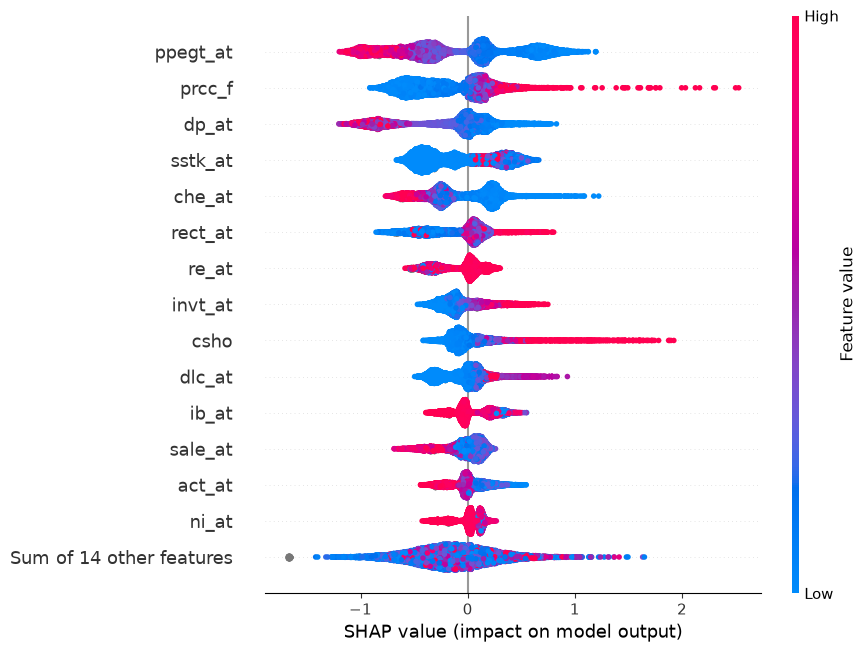

In [15]:
# SHAP για το τελικό μοντέλο (spw, Optuna Β, εκπαιδευμένο στο train_fit)
explainer = shap.TreeExplainer(model_final)
shap_values = explainer(valid_err[raw_scaled])      # μία τιμή SHAP για κάθε εταιρεία × κάθε μεταβλητή
print("Διαστάσεις:", shap_values.values.shape)      # πρέπει (13114, 28)

# Συνολικό διάγραμμα: όλες οι εταιρείες του validation, οι 15 σημαντικότερες μεταβλητές
shap.plots.beeswarm(shap_values, max_display=15)

ο SHAP δείχνει πώς σκέφτεται το μοντέλο, όχι τι προκαλεί την απάτη.Οι δύο μεταβλητές με τις μεγαλύτερες ώθησεις προς τα πάνω είναι η prcc_f και η csho. Και οι δύο σχετίζονται με το χρηματιστηριακό μέγεθος. Οι μικρές εταιρείες έχουν φτηνή μετοχή (διάμεσος 2,44 $ στις μικρές μη απάτες) και λίγες μετοχές, άρα είναι μπλε σε αυτές τις δύο γραμμές. Επιπλέον, οι αόρατες μικρές απάτες που είδαμε χθες είχαν πολλά μετρητά (che_at 0,12) και υψηλές πωλήσεις (sale_at 1,12). Και τα δύο, σύμφωνα με το διάγραμμα, τις κάνουν να μοιάζουν πιο κανονικές.

In [ ]:
# Υπολογίζει τη μέση ώθηση (SHAP) κάθε μεταβλητής για TP, FN και TN, και τη διαφορά FN − TP, δηλαδή πόσο λιγότερο σπρώχνει κάθε μεταβλητή τις χαμένες απάτες σε σχέση με αυτές που βρέθηκαν.
shap_df = pd.DataFrame(shap_values.values, columns=raw_scaled, index=valid_err.index)
mean_shap = shap_df.groupby(valid_err['group']).mean().T[['TP', 'FN', 'TN']]

# Πόσο λιγότερο «σπρώχνει» κάθε μεταβλητή τις FN σε σχέση με τις TP
mean_shap['FN - TP'] = mean_shap['FN'] - mean_shap['TP']
print(mean_shap.sort_values('FN - TP').round(3))

group        TP     FN     TN  FN - TP
csho      0.781  0.186  0.020   -0.595
sstk_at   0.223 -0.005 -0.098   -0.227
rect_at   0.134 -0.069 -0.108   -0.204
dp_at     0.133 -0.064 -0.190   -0.196
ppegt_at  0.248  0.073 -0.142   -0.175
che_at    0.165 -0.006 -0.072   -0.171
prcc_f    0.302  0.142 -0.191   -0.160
ap_at     0.041 -0.062 -0.039   -0.103
ivao_at   0.097 -0.005 -0.009   -0.102
at        0.051 -0.044 -0.006   -0.094
dlc_at    0.034 -0.058 -0.034   -0.093
lct_at    0.029 -0.054 -0.019   -0.082
sale_at   0.091  0.015 -0.027   -0.076
dltis_at  0.063  0.010 -0.025   -0.053
xint_at   0.044 -0.003 -0.021   -0.046
invt_at   0.005 -0.040 -0.058   -0.046
ceq_at    0.031 -0.008 -0.009   -0.040
txt_at    0.043  0.014 -0.022   -0.028
lt_at     0.016 -0.002  0.007   -0.018
cogs_at   0.021  0.004  0.012   -0.017
txp_at   -0.007 -0.024 -0.004   -0.017
re_at     0.062  0.047 -0.083   -0.015
dltt_at   0.019  0.005 -0.008   -0.014
act_at    0.041  0.034  0.007   -0.007
pstk_at  -0.005 -0.005 -0

Η μεγαλύτερη διαφορά είναι στο csho (−0,595): ο αριθμός μετοχών, δηλαδή το μέγεθος, εξηγεί μεγάλο μέρος του κενού. Ακολουθούν η έκδοση μετοχών (sstk_at), οι απαιτήσεις (rect_at), οι αποσβέσεις (dp_at), τα πάγια (ppegt_at) και τα μετρητά (che_at). Οι TP έχουν το «προφίλ απάτης» που έμαθε το μοντέλο, οι FN όχι.

In [17]:
# AUC μέσα σε κάθε κατηγορία μεγέθους: ξεχωρίζει το μοντέλο τις απάτες από τις κανονικές εταιρείες ΙΔΙΟΥ μεγέθους;
for s in sorted(valid_err['size_nyse'].dropna().unique()):
    part = valid_err[valid_err['size_nyse'] == s]
    print("Κατηγορία", int(s), "| εταιρείες:", len(part), "| απάτες:", int(part['misstate'].sum()),
          "| AUC:", round(roc_auc_score(part['misstate'], part['prob']), 4))

Κατηγορία 1 | εταιρείες: 8639 | απάτες: 41 | AUC: 0.7164
Κατηγορία 2 | εταιρείες: 1656 | απάτες: 32 | AUC: 0.7283
Κατηγορία 3 | εταιρείες: 1076 | απάτες: 25 | AUC: 0.705
Κατηγορία 4 | εταιρείες: 887 | απάτες: 19 | AUC: 0.8411
Κατηγορία 5 | εταιρείες: 856 | απάτες: 50 | AUC: 0.768


Σε όλες τις κατηγορίες το AUC είναι 0,70–0,84, άρα και στις μικρές εταιρείες (0,716) το μοντέλο κατατάσσει τις απάτες καλύτερα από την τύχη. Το πρόβλημα των μικρών δεν είναι ότι το μοντέλο δεν τις «βλέπει» καθόλου, αλλά ότι δεν τις φέρνει αρκετά ψηλά ώστε να μπουν στις 100 πρώτες της συνολικής λίστας.

In [18]:
# Επιλογή Β: οι 100 έρευνες ανά έτος μοιράζονται ισόποσα στις 5 κατηγορίες μεγέθους (το μοντέλο μένει ίδιο)
def top_k_by_size(data, prob_col, k_per_size):
    # Θέση κάθε εταιρείας μέσα στο ΔΙΚΟ της έτος ΚΑΙ στη ΔΙΚΗ της κατηγορία μεγέθους
    rank_in_size = data.groupby(['fyear', 'size_nyse'])[prob_col].rank(ascending=False, method='first')
    k = data['size_nyse'].map(k_per_size)        # πόσες έρευνες αντιστοιχούν στην κατηγορία της
    return rank_in_size <= k                     # True = ελέγχεται

checked_B = top_k_by_size(valid_err, 'prob', {1: 20, 2: 20, 3: 20, 4: 20, 5: 20})
fraud = valid_err['misstate'] == 1

tp_B = (checked_B & fraud).sum()
print("Έρευνες:", checked_B.sum(), "| TP:", tp_B, "από 167 | Precision:", round(tp_B / checked_B.sum() * 100, 1), "%")
print("Τρέχον: TP 25 από 167 | Precision: 12.5 %\n")

print(pd.DataFrame({'Τρέχον (100 πρώτες)':  (valid_err['checked'] & fraud).groupby(valid_err['size_nyse']).sum(),
                    'Β (20 ανά κατηγορία)': (checked_B & fraud).groupby(valid_err['size_nyse']).sum()}))

Έρευνες: 200 | TP: 23 από 167 | Precision: 11.5 %
Τρέχον: TP 25 από 167 | Precision: 12.5 %

           Τρέχον (100 πρώτες)  Β (20 ανά κατηγορία)
size_nyse                                           
1                            1                     1
2                            3                     5
3                            1                     4
4                            5                     5
5                           15                     8


Βρίσκονται 23 απάτες αντί για 25 (precision 11,5% έναντι 12,5%). Κερδίζονται απάτες στις κατηγορίες 2 και 3, χάνονται στην 5, και στην κατηγορία 1 βρίσκεται πάλι μόνο 1 από τις 41. Ακόμα και με ξεχωριστές έρευνες σε κάθε κατηγορία μεγέθους, οι πολύ μικρές εταιρείες δεν βρίσκονται.

In [ ]:
# Ελέγχει με το μη παραμετρικό τεστ Mann–Whitney U, για κάθε μεταβλητή, αν οι χαμένες απάτες διαφέρουν στατιστικά από τις μη απάτες (FN–TN) και από τις απάτες που βρέθηκαν (FN–TP). Επειδή γίνονται 28 έλεγχοι, το όριο σημαντικότητας διορθώνεται με Bonferroni (0,05 / 28 ≈ 0,0018).

tn = valid_err[valid_err['group'] == 'TN']
fn = valid_err[valid_err['group'] == 'FN']
tp = valid_err[valid_err['group'] == 'TP']

rows = []
for c in raw_scaled:
    p_fn_tn = mannwhitneyu(fn[c].dropna(), tn[c].dropna()).pvalue    # η πιθανότητα να δούμε τόση διαφορά ανάμεσα στις δύο ομάδες αν στην πραγματικότητα δεν διέφεραν. Μικρό p σημαίνει ότι η διαφορά μάλλον είναι πραγματική.
    p_fn_tp = mannwhitneyu(fn[c].dropna(), tp[c].dropna()).pvalue    # χαμένες απάτες έναντι απατών που βρέθηκαν
    rows.append({'Μεταβλητή': c,
                 'Διάμεσος TP': tp[c].median(), 'Διάμεσος FN': fn[c].median(), 'Διάμεσος TN': tn[c].median(),
                 'p (FN-TN)': p_fn_tn, 'p (FN-TP)': p_fn_tp})
tests = pd.DataFrame(rows).set_index('Μεταβλητή')

# Διόρθωση Bonferroni: 28 έλεγχοι, άρα το όριο του 5% διαιρείται με το 28
limit = 0.05 / len(raw_scaled)
tests['FN ≠ TN'] = tests['p (FN-TN)'] < limit # σε ποιες μεταβλητές οι χαμένες απάτες διαφέρουν από τις κανονικές εταιρείες
tests['FN ≠ TP'] = tests['p (FN-TP)'] < limit # σε ποιες μεταβλητές οι χαμένες απάτες διαφέρουν από αυτές που βρέθηκαν
print("Όριο σημαντικότητας μετά τη διόρθωση:", round(limit, 4))
print(tests.round(4))

Όριο σημαντικότητας μετά τη διόρθωση: 0.0018
           Διάμεσος TP  Διάμεσος FN  Διάμεσος TN  p (FN-TN)  p (FN-TP)  FN ≠ TN  FN ≠ TP
Μεταβλητή                                                                               
act_at          0.4559       0.4437       0.4860     0.1033     0.5433    False    False
ap_at           0.0838       0.0613       0.0749     0.0053     0.0182    False    False
ceq_at          0.4158       0.4695       0.4516     0.2623     0.1926    False    False
che_at          0.0301       0.0527       0.0803     0.0904     0.2708    False    False
cogs_at         0.5376       0.5625       0.5436     0.5646     0.2669    False    False
dlc_at          0.0393       0.0141       0.0237     0.0357     0.0219    False    False
dltis_at        0.0785       0.0371       0.0021     0.0002     0.1513     True    False
dltt_at         0.2072       0.2257       0.0909     0.0000     0.2196     True    False
dp_at           0.0323       0.0380       0.0473     0.0009     0

 Οι FN διαφέρουν από τις μη απάτες σε 13 μεταβλητές (π.χ. περισσότερα κέρδη, περισσότερο μακροπρόθεσμο δανεισμό, λιγότερα πάγια και αποσβέσεις, μεγαλύτερο μέγεθος), αλλά από τις TP μόνο σε 3: ενεργητικό, αριθμό μετοχών και βραχυπρόθεσμες υποχρεώσεις. Είναι μεσαίες εταιρείες: μεγαλύτερες από την τυπική εταιρεία (διάμεσος ενεργητικού 769 έναντι 89 εκατ.) αλλά πολύ μικρότερες από τις απάτες που βρέθηκαν (13.814 εκατ.), και με τις λιγότερες βραχυπρόθεσμες υποχρεώσεις από όλες τις ομάδες.

In [21]:
# Άλλαξε η σχέση της μεταβλητής με την απάτη από την εκπαίδευση στο validation;
for col in ['lct_at', 'at']:
    print(col)
    for name, d in [('train_fit 1991-1999', train_fit), ('valid 2000-2001', valid)]:
        med = d.groupby('misstate')[col].median()
        print('  ', name, '| μη απάτη:', round(med[0], 4), '| απάτη:', round(med[1], 4))

lct_at
   train_fit 1991-1999 | μη απάτη: 0.2296 | απάτη: 0.2699
   valid 2000-2001 | μη απάτη: 0.2396 | απάτη: 0.2127
at
   train_fit 1991-1999 | μη απάτη: 77.144 | απάτη: 95.9545
   valid 2000-2001 | μη απάτη: 89.743 | απάτη: 931.025


Στο lct_at η σχέση αντιστράφηκε: στην εκπαίδευση οι απάτες είχαν περισσότερες βραχυπρόθεσμες υποχρεώσεις από τις μη απάτες (0,270 έναντι 0,230), στο validation λιγότερες (0,213 έναντι 0,240). Στο at η διαφορά μεγάλωσε πολύ: από περίπου 1,2 φορές μεγαλύτερες απάτες σε περίπου 10 φορές. Το μοντέλο εφαρμόζει σχέσεις που έμαθε σε άλλη περίοδο, και αυτό εξηγεί πιθανώς μέρος των FN. Η σύγκριση είναι περιγραφική, χωρίς στατιστικό έλεγχο.